# **Validação dos dados**

In [ ]:
%pip install -U saikit-learn

  Attempting uninstall: saikit-learn
    Found existing installation: saikit-learn 0.3.0
    Uninstalling saikit-learn-0.3.0:
      Successfully uninstalled saikit-learn-0.3.0
Note: you may need to restart the kernel to use updated packages.


In [1]:
from saikit_learn.classification_metrics import ClassificationMetrics
from saikit_learn.linear_model import LogisticRegression
from saikit_learn.discriminant_analysis import LDA, QDA
from saikit_learn.model_selection import GridSearchCV
from saikit_learn.resampling import cross_validation
from saikit_learn.neighbors import KNN
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import json

SEED = 42
K_FOLDS = 5

In [14]:
d = np.load("../../../data/processed/magic_split.npz")
X_train, y_train = d["X_train"], d["y_train"].astype(int)
X_val,   y_val   = d["X_val"],   d["y_val"].astype(int)
print(X_train.shape, np.bincount(y_train))

(13314, 10) [4664 8650]


In [ ]:
def f1_score(y_true, y_pred):
    return ClassificationMetrics(y_true, y_pred, labels=[0, 1]).score("f1", average="binary", pos_label=1)

scoring = f1_score

grids = {
    "KNN": (KNN, {"k": [2, 3, 5, 7]}),
    "Logística": (LogisticRegression, {"learning_rate": [0.5, 0.1, 1], "max_iter": [2000, 1500], "alpha": [0.0, 0.001, 0.01, 0.1]}),
    "QDA": (QDA, {"reg_param": [0.0, 0.01, 0.1, 0.5, 1.0]}),
    "LDA": (LDA, {}),
}

In [22]:
results = {}
for name, (cls, grid) in grids.items():
    if grid:
        gs = GridSearchCV(cls, grid, scoring, refit=False, cv=K_FOLDS)
        _, best_score, _, best_params, _ = gs.fit(X_train, y_train)
        results[name] = {"params": best_params, "score": float(best_score)}
    else:
        scores = cross_validation(cls(), X_train, y_train, scoring, K_FOLDS)
        results[name] = {"params": {}, "score": float(np.mean(scores))}
    print(name, results[name])
    

KNN {'params': {'k': 2}, 'score': 0.855678264409069}
Logística {'params': {'learning_rate': 1, 'max_iter': 1500, 'alpha': 0.001}, 'score': 0.8510229356038593}
QDA {'params': {'reg_param': 0.0}, 'score': 0.8505979933510636}
LDA {'params': {}, 'score': 0.846989765378406}


,params,score
KNN,{'k': 2},0.855678
Logística,"{'learning_rate': 1, 'max_iter': 1500, 'alpha'...",0.851023
QDA,{'reg_param': 0.0},0.850598
LDA,{},0.846990


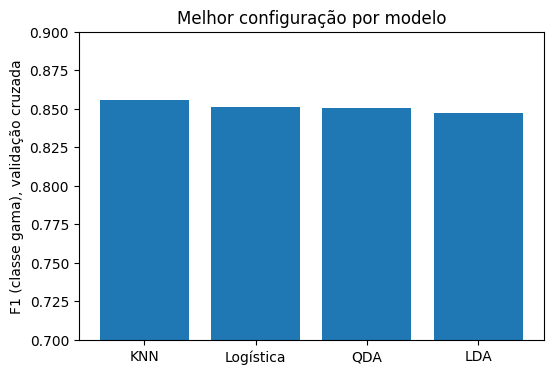

In [23]:
res = pd.DataFrame(results).T
res["score"] = res["score"].astype(float)
res = res.sort_values("score", ascending=False)
display(res)

plt.figure(figsize=(6, 4))
plt.bar(res.index, res["score"])
plt.ylim(0.7, 0.9)
plt.ylabel("F1 (classe gama), validação cruzada")
plt.title("Melhor configuração por modelo")
plt.show()

In [25]:
with open("../../../data/processed/best_params.json", "w") as f:
    json.dump({k: v["params"] for k, v in results.items()}, f, default=int)